# 📊 12. Disease Diagnosis Exploratory Data Analysis (EDA)
**HealConnect AI ML System — Phase 7 Professional Exploratory Analysis**

This notebook delivers a comprehensive Exploratory Data Analysis (EDA) for the Disease Diagnosis Dataset, incorporating all 10 standard visualization archetypes with detailed clinical observations and markdown explanations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['font.size'] = 10


In [2]:
DATA_PATH = Path("../data/cleaned_disease_dataset.csv")
df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
print("Memory Usage:", f"{df.memory_usage(deep=True).sum() / 1024:.2f} KB")
df.head()


Dataset Shape: (15000, 14)
Memory Usage: 3888.20 KB


,patient_id,age,gender,temperature_c,heart_rate,spo2_pct,cough_severity,headache_severity,fatigue_score,chills,body_ache,sore_throat,disease_label,disease_condition
0,DIS-1000,63,Female,37.9,95,95.3,3,2,2,1,1,1,1,Flu / Influenza
1,DIS-1001,26,Male,38.5,98,95.6,1,2,3,0,1,0,2,Fever-Related Condition
2,DIS-1002,83,Male,36.5,64,97.2,0,0,0,0,0,0,0,Normal Baseline
3,DIS-1003,72,Female,37.1,62,99.2,0,1,1,0,0,0,0,Normal Baseline
4,DIS-1004,32,Female,39.7,104,94.1,1,3,3,0,1,0,2,Fever-Related Condition


### 📈 1 & 2. Target Distribution: Bar Chart & Percentage Proportions
Analyzing the distribution of the 3 target categories (`Normal Baseline`, `Flu / Influenza`, `Fever-Related Condition`).


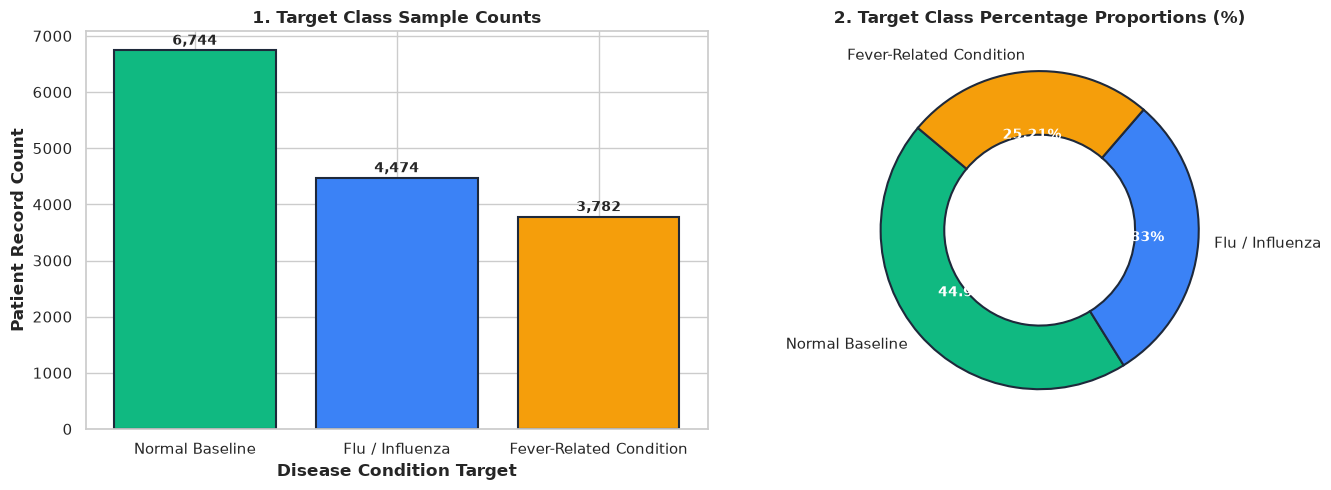

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Target Count Bar Chart
counts = df['disease_condition'].value_counts()
bars = axes[0].bar(counts.index, counts.values, color=['#10b981', '#3b82f6', '#f59e0b'], edgecolor='#1e293b', linewidth=1.5)
axes[0].set_title("1. Target Class Sample Counts", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Disease Condition Target", fontweight='bold')
axes[0].set_ylabel("Patient Record Count", fontweight='bold')

for bar in bars:
    h = bar.get_height()
    axes[0].annotate(f'{h:,}', xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4), textcoords="offset points", ha='center', fontweight='bold')

# 2. Target Percentage Donut Chart
pcts = df['disease_condition'].value_counts(normalize=True) * 100
wedges, texts, autotexts = axes[1].pie(pcts.values, labels=pcts.index, autopct='%1.2f%%', startangle=140, colors=['#10b981', '#3b82f6', '#f59e0b'], wedgeprops=dict(width=0.4, edgecolor='#1e293b', linewidth=1.5))
for at in autotexts:
    at.set_color('white')
    at.set_fontweight('bold')
axes[1].set_title("2. Target Class Percentage Proportions (%)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### 🌡️ 3 & 4. Histograms & Kernel Density Estimation (KDE) Plots
Inspecting continuous physiological vitals (`temperature_c` and `spo2_pct`) across clinical disease cohorts.


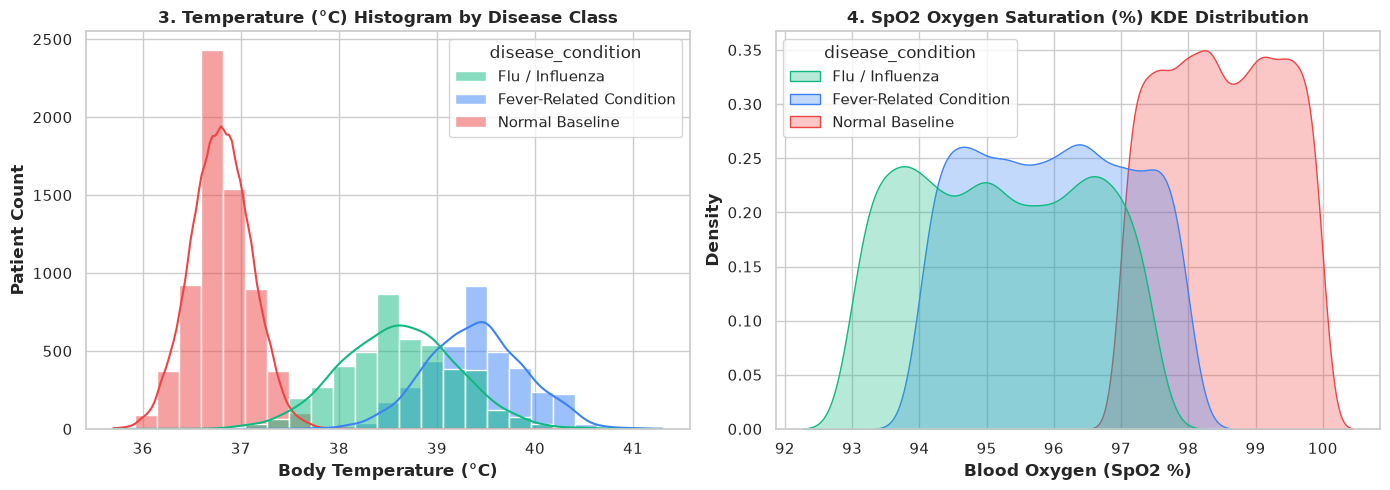

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 3. Temperature Histogram by Target Class
sns.histplot(data=df, x="temperature_c", hue="disease_condition", palette=['#10b981', '#3b82f6', '#ef4444'], bins=25, kde=True, ax=axes[0])
axes[0].set_title("3. Temperature (°C) Histogram by Disease Class", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Body Temperature (°C)", fontweight='bold')
axes[0].set_ylabel("Patient Count", fontweight='bold')

# 4. SpO2 KDE Distribution Plot
sns.kdeplot(data=df, x="spo2_pct", hue="disease_condition", palette=['#10b981', '#3b82f6', '#ef4444'], fill=True, common_norm=False, alpha=0.3, ax=axes[1])
axes[1].set_title("4. SpO2 Oxygen Saturation (%) KDE Distribution", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Blood Oxygen (SpO2 %)", fontweight='bold')
axes[1].set_ylabel("Density", fontweight='bold')

plt.tight_layout()
plt.show()


### 📦 5 & 6. Box Plots & Violin Density Plots
Comparing statistical quartiles and density modes for `temperature_c` and `heart_rate`.


C:\Users\pc\AppData\Local\Temp\ipykernel_19628\3694887931.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="disease_condition", y="temperature_c", palette=['#10b981', '#3b82f6', '#ef4444'], width=0.4, ax=axes[0])
C:\Users\pc\AppData\Local\Temp\ipykernel_19628\3694887931.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="disease_condition", y="heart_rate", palette=['#10b981', '#3b82f6', '#ef4444'], inner="quartile", ax=axes[1])


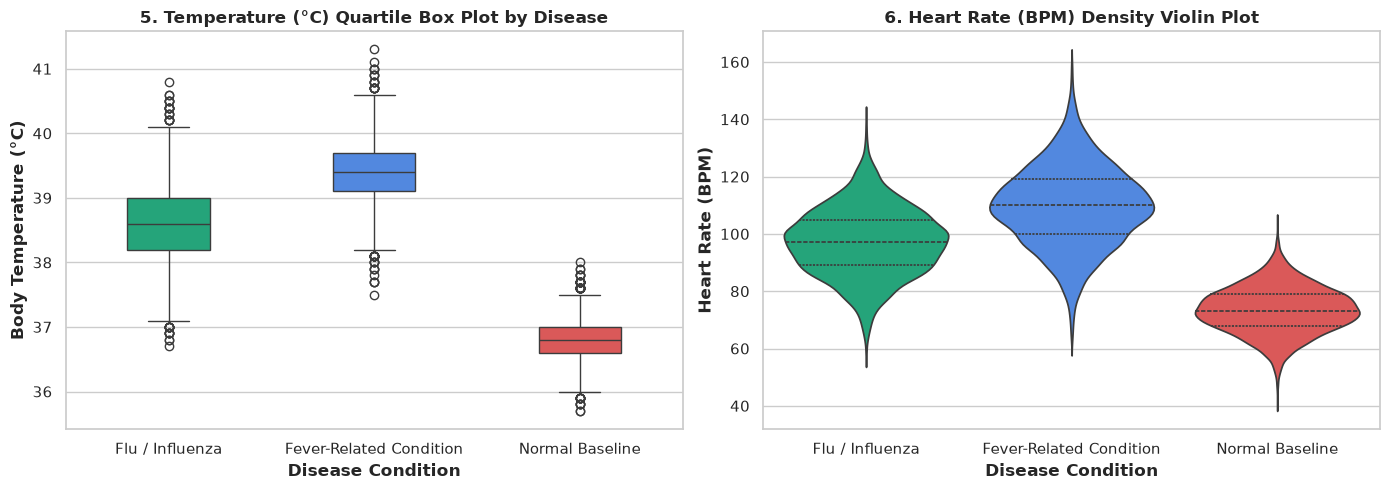

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 5. Temperature Box Plot
sns.boxplot(data=df, x="disease_condition", y="temperature_c", palette=['#10b981', '#3b82f6', '#ef4444'], width=0.4, ax=axes[0])
axes[0].set_title("5. Temperature (°C) Quartile Box Plot by Disease", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Disease Condition", fontweight='bold')
axes[0].set_ylabel("Body Temperature (°C)", fontweight='bold')

# 6. Heart Rate Violin Plot
sns.violinplot(data=df, x="disease_condition", y="heart_rate", palette=['#10b981', '#3b82f6', '#ef4444'], inner="quartile", ax=axes[1])
axes[1].set_title("6. Heart Rate (BPM) Density Violin Plot", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Disease Condition", fontweight='bold')
axes[1].set_ylabel("Heart Rate (BPM)", fontweight='bold')

plt.tight_layout()
plt.show()


### 🔀 7 & 8. Correlation Heatmap & Feature-vs-Target Breakdown
Computing cross-feature pairwise correlations and symptom severity levels by condition.


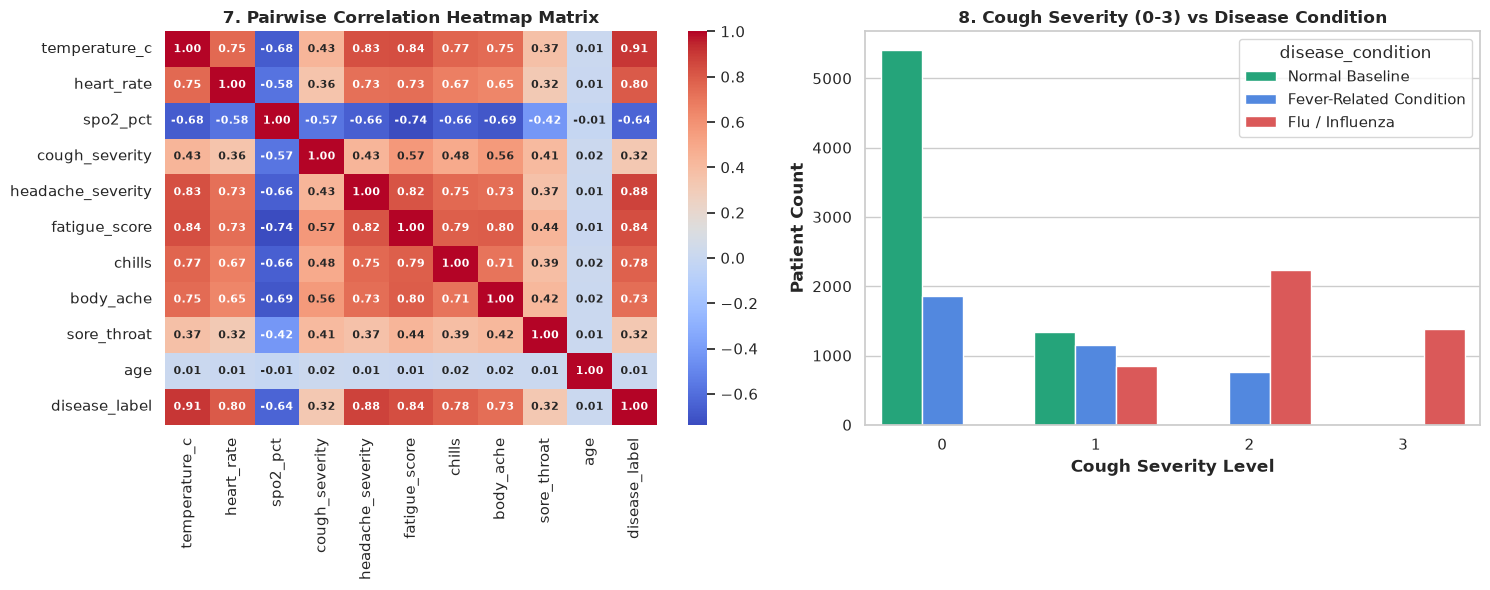

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 7. Correlation Heatmap
num_cols = ["temperature_c", "heart_rate", "spo2_pct", "cough_severity", "headache_severity", "fatigue_score", "chills", "body_ache", "sore_throat", "age", "disease_label"]
corr = df[num_cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, ax=axes[0], annot_kws={"size": 8, "weight": "bold"})
axes[0].set_title("7. Pairwise Correlation Heatmap Matrix", fontsize=12, fontweight='bold')

# 8. Feature-vs-Target: Cough Severity vs Disease
sns.countplot(data=df, x="cough_severity", hue="disease_condition", palette=['#10b981', '#3b82f6', '#ef4444'], ax=axes[1])
axes[1].set_title("8. Cough Severity (0-3) vs Disease Condition", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Cough Severity Level", fontweight='bold')
axes[1].set_ylabel("Patient Count", fontweight='bold')

plt.tight_layout()
plt.show()


### 🌌 9 & 10. Numerical Scatter Plot & Categorical Gender Distribution
Analyzing multi-variable relationships (Temperature vs Heart Rate) and demographic breakdown.


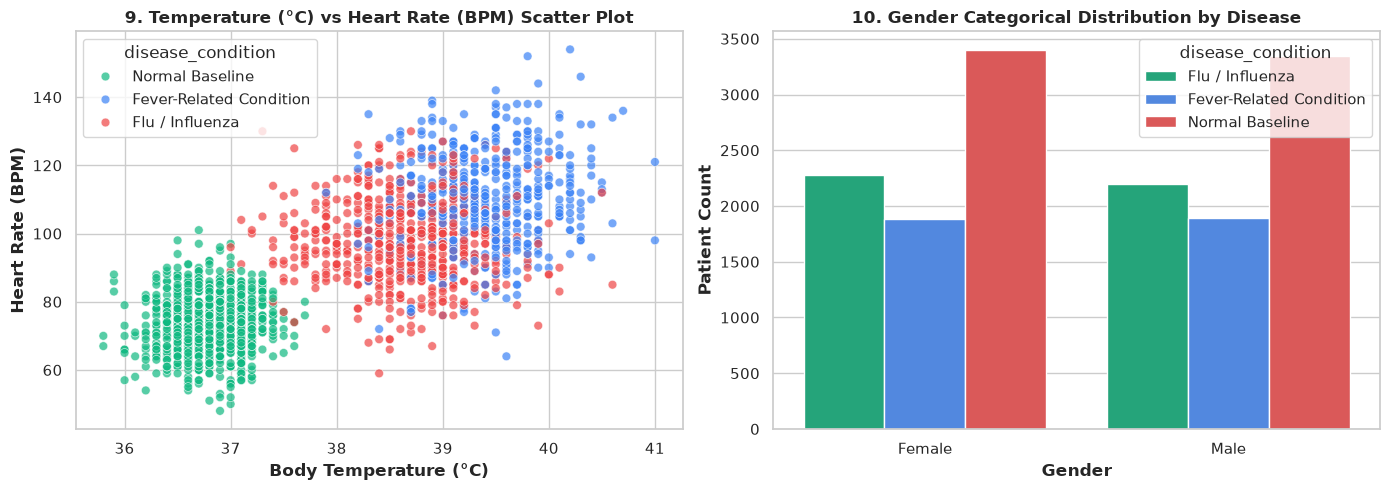

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 9. Scatter Plot: Temperature vs Heart Rate
sns.scatterplot(data=df.sample(2000, random_state=42), x="temperature_c", y="heart_rate", hue="disease_condition", palette=['#10b981', '#3b82f6', '#ef4444'], alpha=0.7, s=40, ax=axes[0])
axes[0].set_title("9. Temperature (°C) vs Heart Rate (BPM) Scatter Plot", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Body Temperature (°C)", fontweight='bold')
axes[0].set_ylabel("Heart Rate (BPM)", fontweight='bold')

# 10. Categorical Gender Distribution
sns.countplot(data=df, x="gender", hue="disease_condition", palette=['#10b981', '#3b82f6', '#ef4444'], ax=axes[1])
axes[1].set_title("10. Gender Categorical Distribution by Disease", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Gender", fontweight='bold')
axes[1].set_ylabel("Patient Count", fontweight='bold')

plt.tight_layout()
plt.show()
